# Lab 5 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab05.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import torch
import lab05

NPZ = '../data/parts_shapes.npz'
X, y = lab05.load_data(NPZ)
CLASSES = [str(c) for c in np.load(NPZ, allow_pickle=False)['classes']]
results = lab05.run_experiment(X, y)
results

{'baseline': {'accuracy': 0.2573, 'trainable_params': 0},
 'scratch': {'accuracy': 0.8219, 'trainable_params': 7940},
 'transfer': {'accuracy': 0.9469, 'trainable_params': 2052}}

## Plot 1 — What the images look like

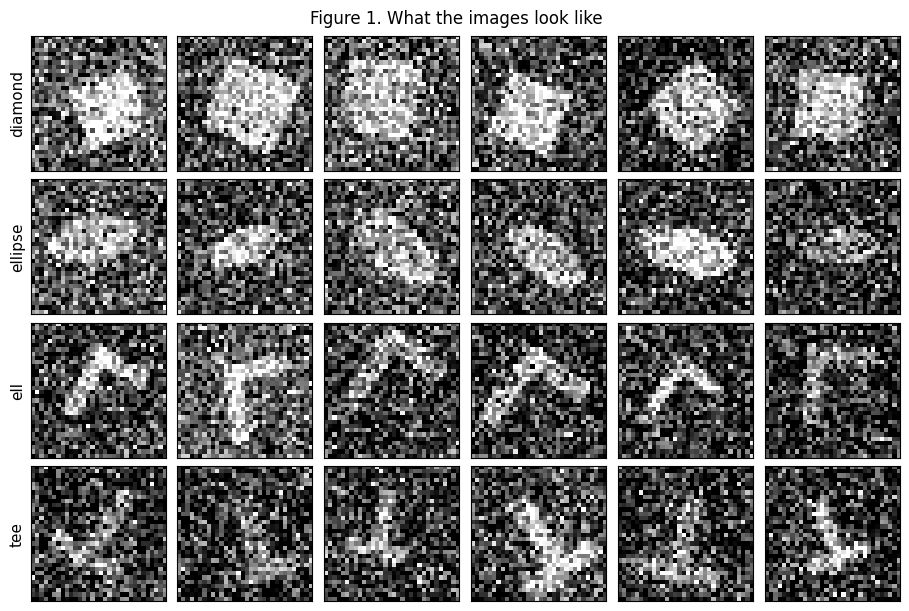

In [2]:
# ============ TODO (Plot 1) ============
# 4 rows (one per class) x 6 columns of sample images from X.
# plt.imshow(X[i, 0], cmap='gray'); no ticks; label each row with CLASSES[c].
# Look at them: which two classes would you expect the model to confuse?
# =======================================

# ① 클래스마다 한 행, 샘플마다 한 열인 격자 생성
fig1, sample_axes = plt.subplots(
    nrows=len(CLASSES),
    ncols=6,
    figsize=(9, 6),
    squeeze=False,
    constrained_layout=True,
)

# ② 클래스별로 샘플 이미지 6개 선택
for c, class_name in enumerate(CLASSES):
    indices = torch.where(y == c)[0][:6]
    assert len(indices) == 6

    # ③ 선택한 이미지를 해당 행에 표시
    for col, idx in enumerate(indices):
        ax = sample_axes[c, col]

        ax.imshow(
            X[int(idx), 0].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )

        # ④ 눈금 제거
        ax.set_xticks([])
        ax.set_yticks([])

        # ⑤ 각 행 첫 번째 이미지 옆에 클래스 이름 표시
        if col == 0:
            ax.set_ylabel(class_name, fontsize=11)

# ⑥ 제목 설정 후 이미지 저장
fig1.suptitle("Figure 1. What the images look like")
fig1.savefig(
    "fig1_samples.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Plot 2 — How the gap depends on the number of labels

n= 60 | scratch=0.4377 | transfer=0.7439
n=120 | scratch=0.6500 | transfer=0.8907
n=240 | scratch=0.8219 | transfer=0.9469
n=480 | scratch=0.9014 | transfer=0.9681
n=900 | scratch=0.9667 | transfer=0.9800


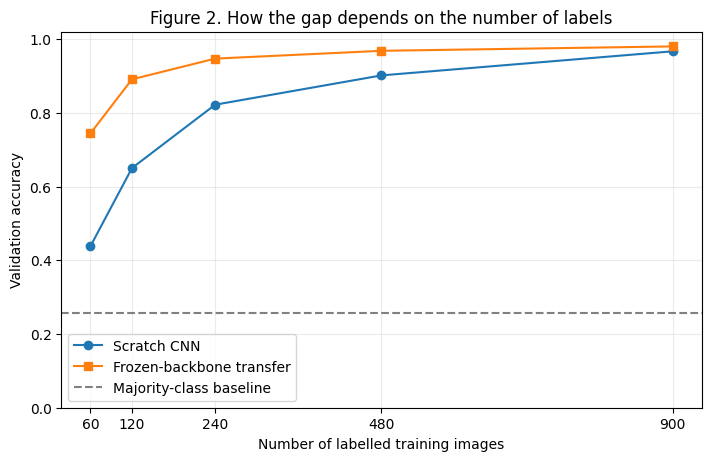

In [3]:
# ============ TODO (Plot 2) ============
# Validation accuracy against the size of the labelled training set.
# For each n in [60, 120, 240, 480, 900]:
#   X_tr, X_val, y_tr, y_val = lab05.split_data(X, y, n_train=n)
#   train a scratch model and a transfer model exactly as run_experiment does
#   (lab05.set_seed() before building each one), and record both accuracies.
# Plot two lines against n, plus a dashed horizontal line at results['baseline']['accuracy'].
# This cell takes about 15 seconds.
# =======================================

# ① 사용할 학습 데이터 개수와 정확도 저장 공간 준비
budgets = [60, 120, 240, 480, 900]
scratch_accs = []
transfer_accs = []

# ② 각 학습 데이터 개수에 대해 실험
for n in budgets:
    X_tr, X_val, y_tr, y_val = lab05.split_data(
        X,
        y,
        n_train=n,
    )

    # ③ 시드 초기화 후 scratch 모델 생성·학습·평가
    lab05.set_seed()

    scratch_model = lab05.build_cnn(lab05.N_CLASSES)
    lab05.train_model(scratch_model, X_tr, y_tr)

    scratch_pred = lab05.predict(scratch_model, X_val)
    scratch_acc = lab05.accuracy(y_val, scratch_pred)
    scratch_accs.append(scratch_acc)

    # ④ 시드를 다시 초기화한 후 transfer 모델 생성·학습·평가
    lab05.set_seed()

    transfer_model = lab05.build_transfer_model(
        lab05.N_CLASSES,
        lab05.WEIGHTS_PATH,
    )
    lab05.train_model(transfer_model, X_tr, y_tr)

    transfer_pred = lab05.predict(transfer_model, X_val)
    transfer_acc = lab05.accuracy(y_val, transfer_pred)
    transfer_accs.append(transfer_acc)

    print(
        f"n={n:3d} | "
        f"scratch={scratch_acc:.4f} | "
        f"transfer={transfer_acc:.4f}"
    )

# ⑤ 두 모델의 정확도 곡선 그리기
fig2, budget_ax = plt.subplots(
    figsize=(7, 4.5),
    constrained_layout=True,
)

budget_ax.plot(
    budgets,
    scratch_accs,
    marker="o",
    label="Scratch CNN",
)

budget_ax.plot(
    budgets,
    transfer_accs,
    marker="s",
    label="Frozen-backbone transfer",
)

# ⑥ 기본 실험의 majority-class baseline을 점선으로 표시
budget_ax.axhline(
    results["baseline"]["accuracy"],
    color="gray",
    linestyle="--",
    label="Majority-class baseline",
)

# ⑦ 축, 눈금, 범례 설정
budget_ax.set_xlabel("Number of labelled training images")
budget_ax.set_ylabel("Validation accuracy")
budget_ax.set_title("Figure 2. How the gap depends on the number of labels")
budget_ax.set_xticks(budgets)
budget_ax.set_ylim(0, 1.02)
budget_ax.grid(alpha=0.25)
budget_ax.legend()

# ⑧ 그림 저장
fig2.savefig(
    "fig2_label_budget.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Plot 3 — Which classes get confused

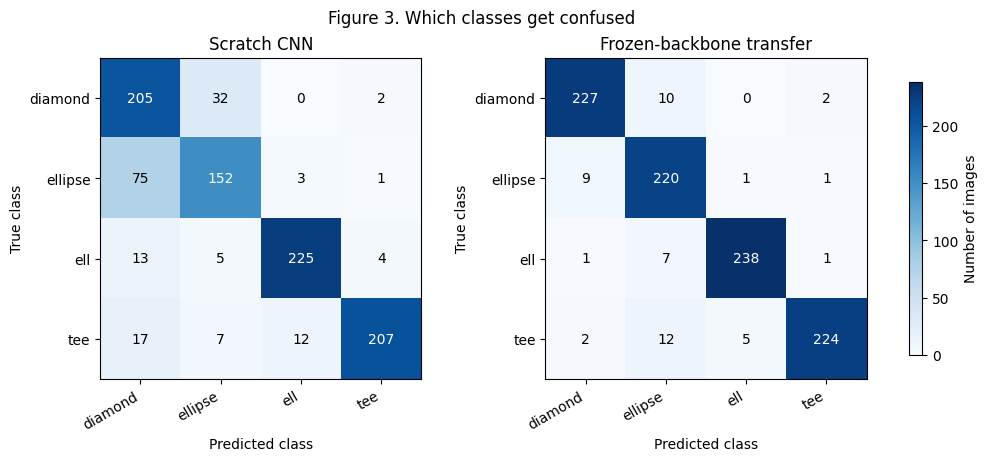

In [5]:
# ============ TODO (Plot 3) ============
# Two 4x4 confusion matrices side by side, scratch and transfer, on the standard
# split (lab05.split_data(X, y)). Rows = true class, columns = predicted class.
# plt.imshow the counts, tick labels from CLASSES, and write each count in its cell.
# =======================================
# ① 기본 훈련 240개 / 검증 960개 split 준비
X_tr, X_val, y_tr, y_val = lab05.split_data(X, y)

true_labels = y_val.numpy()
n_classes = len(CLASSES)

confusion_matrices = []

# ② scratch와 transfer를 각각 새로 학습
for model_name in ("scratch", "transfer"):
    lab05.set_seed()

    if model_name == "scratch":
        model = lab05.build_cnn(lab05.N_CLASSES)
    else:
        model = lab05.build_transfer_model(
            lab05.N_CLASSES,
            lab05.WEIGHTS_PATH,
        )

    lab05.train_model(model, X_tr, y_tr)
    predicted_labels = lab05.predict(model, X_val).numpy()

    # ③ 행=정답, 열=예측인 혼동행렬 생성
    cm = np.zeros(
        (n_classes, n_classes),
        dtype=np.int64,
    )

    # 각 이미지의 (정답 클래스, 예측 클래스) 위치에 1씩 누적
    np.add.at(
        cm,
        (true_labels, predicted_labels),
        1,
    )

    confusion_matrices.append(cm)

# ④ 두 혼동행렬을 나란히 배치
fig3, confusion_axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.5),
    constrained_layout=True,
)

# 두 그림에 같은 색상 범위를 적용
vmax = max(
    int(cm.max())
    for cm in confusion_matrices
)

ticks = np.arange(n_classes)
titles = ("Scratch CNN", "Frozen-backbone transfer")

for ax, title, cm in zip(
    confusion_axes,
    titles,
    confusion_matrices,
):
    # ⑤ 클래스별 개수를 색상으로 표현
    im = ax.imshow(
        cm,
        cmap="Blues",
        vmin=0,
        vmax=vmax,
    )

    # ⑥ 축에 클래스 이름과 방향 표시
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    ax.set_xticklabels(
        CLASSES,
        rotation=30,
        ha="right",
    )
    ax.set_yticklabels(CLASSES)

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)

    # ⑦ 각 셀에 실제 이미지 개수 표시
    for row in range(n_classes):
        for col in range(n_classes):
            value = int(cm[row, col])

            ax.text(
                col,
                row,
                str(value),
                ha="center",
                va="center",
                color=(
                    "white"
                    if value > vmax / 2
                    else "black"
                ),
            )

# ⑧ 공통 colorbar와 전체 제목 추가
fig3.colorbar(
    im,
    ax=confusion_axes.tolist(),
    label="Number of images",
    shrink=0.85,
)

fig3.suptitle("Figure 3. Which classes get confused")

# ⑨ 그림 저장
fig3.savefig(
    "fig3_confusion.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()